# Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

# Load Dataset

In [4]:
df = pd.read_csv("diabetes.csv")
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


# Describe Variables

* *Pregnancies*: The number of times that the person has been pregnant.
* *Glucose*: Βlood sugar levels from a 2 hour oral glucose tolerance test.
* *BloodPressure*: Diastolic blood pressure.
* *SkinThickness*: Triceps skinfold thickness.
* *Insulin*: 2-Hour serum insulin level in mu U/ml. Insulin is an essential hormone. It helps the body turn food into energy and manages blood sugar levels. If a person has diabetes, their body can’t make enough insulin or can’t use it properly.
* *DiabetesPedigreeFunction*: A function that scores the likelihood of diabetes based on family history and genetic heritage.
* *Age*: Person's age in years
* *BMI* (Body Mass Index): Measures the body fat based on weight and height.
* *Outcome*: The result about the person. The value one (1) indicates diabetes.

In [5]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


# Plot Variables

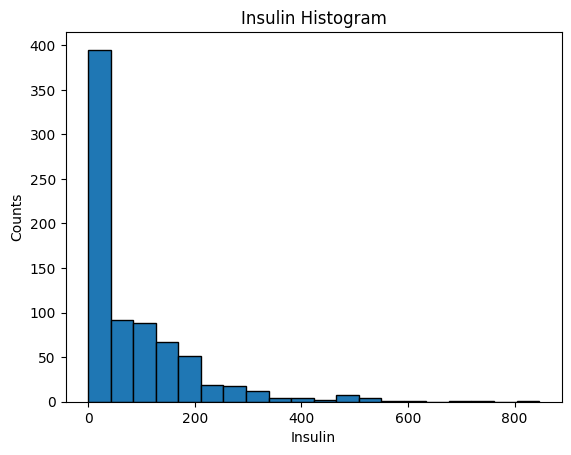

In [6]:
df['Insulin'].hist(bins=20, edgecolor='black')
plt.title('Insulin Histogram')
plt.xlabel('Insulin')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

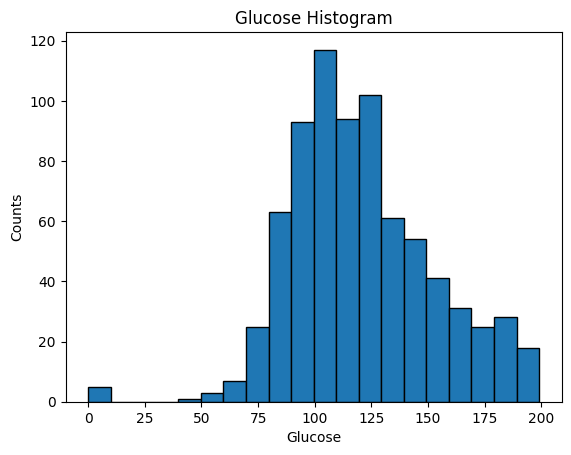

In [7]:
df['Glucose'].hist(bins=20, edgecolor='black')
plt.title('Glucose Histogram')
plt.xlabel('Glucose')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

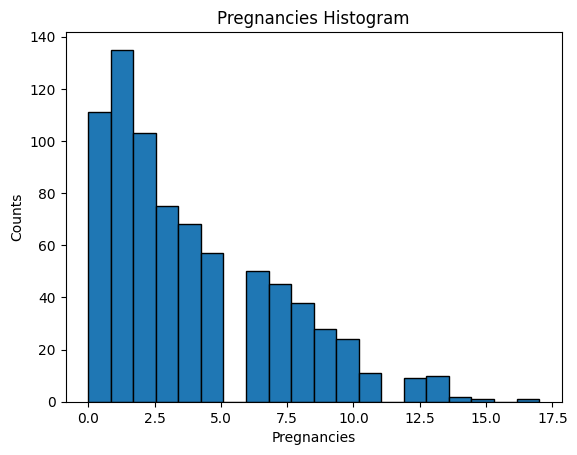

In [8]:
df['Pregnancies'].hist(bins=20, edgecolor='black')
plt.title('Pregnancies Histogram')
plt.xlabel('Pregnancies')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

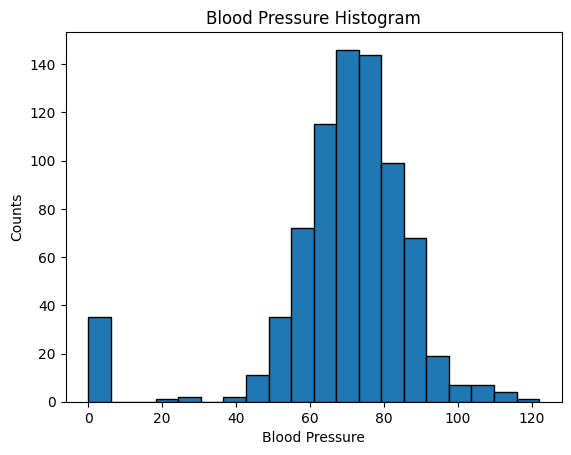

In [9]:
df['BloodPressure'].hist(bins=20, edgecolor='black')
plt.title('Blood Pressure Histogram')
plt.xlabel('Blood Pressure')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

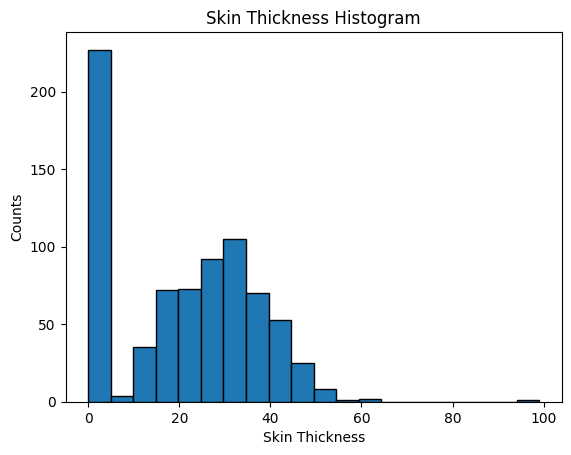

In [10]:
df['SkinThickness'].hist(bins=20, edgecolor='black')
plt.title('Skin Thickness Histogram')
plt.xlabel('Skin Thickness')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

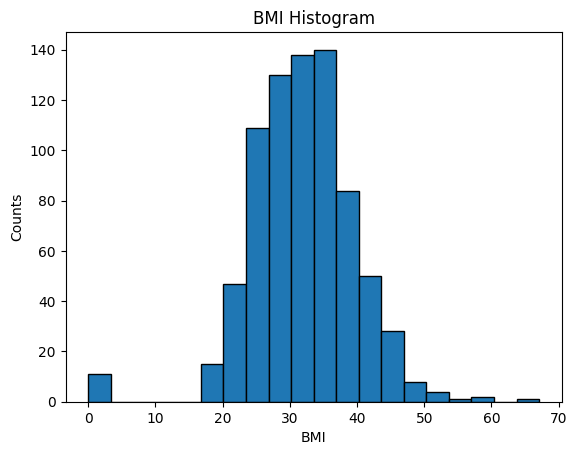

In [11]:
df['BMI'].hist(bins=20, edgecolor='black')
plt.title('BMI Histogram')
plt.xlabel('BMI')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

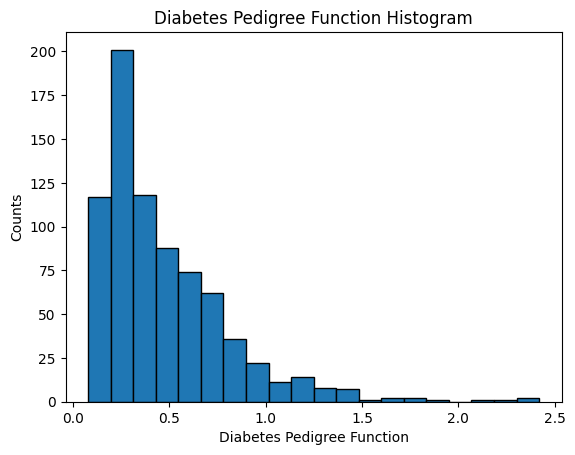

In [12]:
df['DiabetesPedigreeFunction'].hist(bins=20, edgecolor='black')
plt.title('Diabetes Pedigree Function Histogram')
plt.xlabel('Diabetes Pedigree Function')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

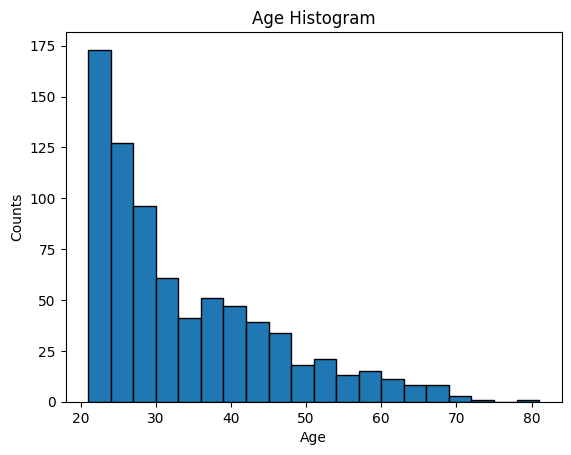

In [13]:
df['Age'].hist(bins=20, edgecolor='black')
plt.title('Age Histogram')
plt.xlabel('Age')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

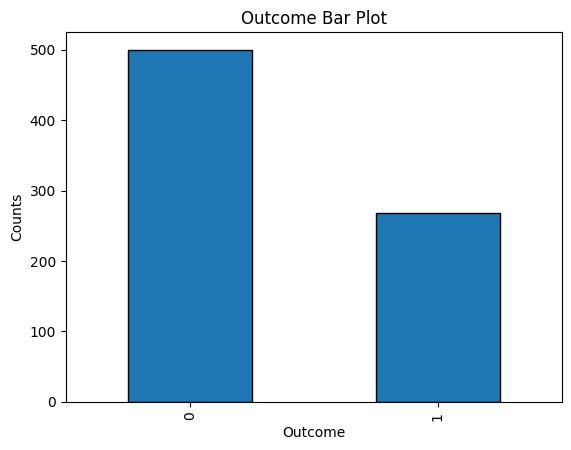

In [14]:
df['Outcome'].value_counts().plot(kind='bar', edgecolor='black')
plt.title('Outcome Bar Plot')
plt.xlabel('Outcome')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

# Convert DataFrame to Numpy arrays

In [16]:
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape


((768, 8), (768,))

# Split Dataset to Train-Test

*Train Samples*: 537

*Test Samples*: 231

*Seed*: 0

Seed enables reproducibility

In [17]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((537, 8), (537,), (231, 8), (231,))

# Create a Logistic Regression Model

In [18]:
model = LogisticRegression(max_iter=5000, random_state=seed)

# Train model on training set

In [19]:
model.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=0)

In [20]:
y_train_pred = model.predict(x_train)
accuracy_train = accuracy_score(y_train, y_train_pred)
accuracy_train_percentage = round(accuracy_train * 100, 2)

print(f"Training Accuracy: {accuracy_train_percentage}%")

Training Accuracy: 76.54%


# Evaluate Model on test set

In [21]:
y_pred = model.predict(x_test)

In [22]:
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}')

The accuracy of the model is: 77.92


We can see that the accuracy in *train set* is almost equal with the accuracy in *test set* ~76%. This is what we want generally to achive, because big differentiation in their value indicates underfitting of overfitting.

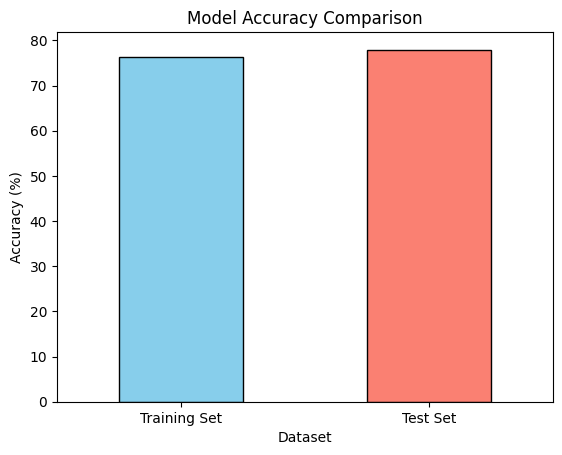

In [77]:
accuracies = pd.Series({'Training Set': accuracy_train_percentage, 'Test Set': accuracy_percentage})

accuracies.plot(kind='bar', edgecolor='black', color=['skyblue', 'salmon'])
plt.title('Model Accuracy Comparison')
plt.xlabel('Dataset')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=0)
plt.grid(False)
plt.show()

# Feature Importance

Retrain the model using standard scaling. Then, investigate coefficients. Larger coefficient values $\rightarrow$ more important features

## Data Normalization

In [23]:
scaler = StandardScaler()
scaler.fit(x_train)

x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

### Model Training-Evaluation

In [24]:
model.fit(x_train, y_train)

y_train_pred = model.predict(x_train)
accuracy_train = accuracy_score(y_train, y_train_pred)
accuracy_train_percentage = round(accuracy_train * 100, 2)

print(f"Training Accuracy: {accuracy_train_percentage}%")

y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}')

Training Accuracy: 76.35%
The accuracy of the model is: 77.92


The Data Normalization alone didn't make any significant improvement to our model...

## Coefficients Investigation

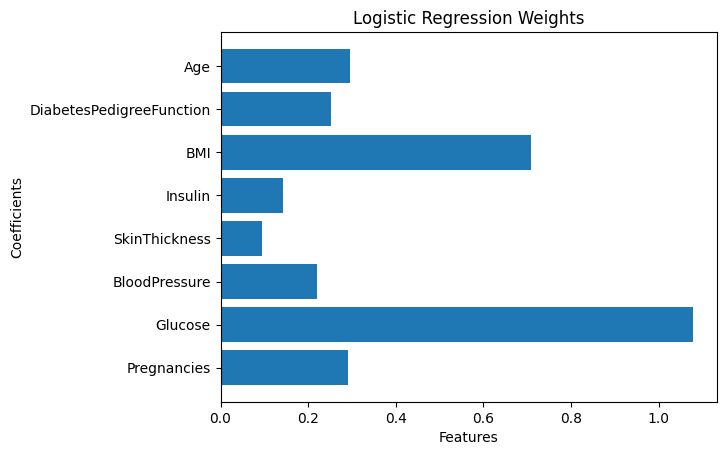

In [25]:
coeffs = model.coef_[0]
importance_weights = np.abs(coeffs)
plt.barh(input_df.columns, importance_weights)
plt.title('Logistic Regression Weights')
plt.xlabel('Features')
plt.ylabel('Coefficients')
plt.show()

We can see that the Glucose weight is very high relatively to the other features. This means that plays an important role, the most important role from all the other features, towards the diabetes result.

Since the weight has a positive value, glucose values level is proportional to the possibily of a person havind diabetes.

# Investigate classifier's accuracy per generation

In [26]:
bins = [0, 25, 50, 120]
labels = ['<25', '26-50', '51+']
df['age_group'] = pd.cut(df['Age'], bins=bins, labels=labels)

df[['Age', 'age_group']].head(10)

,Age,age_group
0,50,26-50
1,31,26-50
2,32,26-50
3,21,<25
4,33,26-50
5,30,26-50
6,26,26-50
7,29,26-50
8,53,51+
9,54,51+


# Part 2

### Create the matrix with the new, fewer features

In [31]:
df = pd.read_csv("diabetes.csv")
new_features = ["Pregnancies", "BloodPressure", "BMI", "Age", "Glucose"]

matrix = df[new_features]

matrix


,Pregnancies,BloodPressure,BMI,Age,Glucose
0,6,72,33.6,50,148
1,1,66,26.6,31,85
2,8,64,23.3,32,183
3,1,66,28.1,21,89
4,0,40,43.1,33,137
...,...,...,...,...,...
763,10,76,32.9,63,101
764,2,70,36.8,27,122
765,5,72,26.2,30,121
766,1,60,30.1,47,126


### Create Numpy arrays with:
*   inputs (x): (Pregnancies, Blood Pressure, BMI, Age)
*   targets (y): (Glucose)



In [33]:
input_matrix = matrix.drop(columns=['Glucose'])
targets_matrix = matrix['Glucose']

x = input_matrix.to_numpy()
y = targets_matrix.to_numpy()
x.shape, y.shape

((768, 4), (768,))

# Split Dataset to Train-Test

*Train Samples*: 537

*Test Samples*: 231

*Seed*: 0

Seed enables reproducibility

In [34]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((537, 4), (537,), (231, 4), (231,))

### Using Linear Regression to predict Glucose values

In [45]:
from sklearn.linear_model import LinearRegression

model_2 = LinearRegression()

model_2.fit(x_train, y_train)

y_test_pred = model_2.predict(x_test)



### Using MSE and MAE to measure accuracy

In [46]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mse = mean_squared_error(y_test, y_test_pred)
print("MSE = ", mse)

mae = mean_absolute_error(y_test, y_test_pred)
print(f"MAE: {mae}")

MSE =  929.8883492746899
MAE: 23.599990462075155


Generally speaking, if we take the square root of the MSE, the value comes out to around ~30. It is relatively close to the MAE, but not excactly the same. However, given the critical nature of the application, it is a medical one, we ideally want to avoid large errors. So, the MSE metric is more appropriate because it gives more penalties to large errors. Furthermore, the fact that the RMSE value is somewhat higher than the MAE says that there are likely some relatively large errors in the predictions. However, the difference between them is not so huge anyway.

### Normalisation and Regularisation

In [76]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

model = LinearRegression()
model.fit(x_scaled, y)

feature_importance_ridge = pd.DataFrame({'Feature': input_matrix.columns, 'Coefficient': np.abs(model.coef_)})
feature_importance_ridge = feature_importance_ridge.sort_values(by='Coefficient')
print(feature_importance_ridge)


         Feature  Coefficient
0    Pregnancies     0.634340
1  BloodPressure     1.172537
2            BMI     6.445390
3            Age     8.250605


For Regularisation I will use Rigde and Lasso class: https://scikit-learn.org/dev/modules/generated/sklearn.linear_model.Ridge.html and https://scikit-learn.org/dev/auto_examples/linear_model/plot_ridge_coeffs.html#sphx-glr-auto-examples-linear-model-plot-ridge-coeffs-py
Ideally, we want big errors to increase the error, so Rigde would be ideal but also our target is feature importance. So we will test both and see

In [75]:
from sklearn.linear_model import Ridge

model_ridge = Ridge(alpha=9.0, max_iter=1000)  # For more testing we could test different alpha values. For now we will stick to
model_ridge.fit(x_scaled, y)

feature_importance_ridge = pd.DataFrame({'Feature': input_matrix.columns, 'Coefficient': np.abs(model_ridge.coef_)})
feature_importance_ridge = feature_importance_ridge.sort_values(by='Coefficient')
print(feature_importance_ridge)

         Feature  Coefficient
0    Pregnancies     0.552373
1  BloodPressure     1.203838
2            BMI     6.365748
3            Age     8.106379


In [73]:
from sklearn.linear_model import Lasso

model_lasso = Lasso(alpha=2, max_iter=1000)  # For more testing we could test different alpha values. For now we will stick to
model_lasso.fit(x_scaled, y)

feature_importance_lasso = pd.DataFrame({'Feature': input_matrix.columns, 'Coefficient': np.abs(model_lasso.coef_)})
feature_importance_lasso = feature_importance_lasso.sort_values(by='Coefficient')
print(feature_importance_lasso)

         Feature  Coefficient
0    Pregnancies     0.000000
1  BloodPressure     0.019152
2            BMI     4.832070
3            Age     6.240045


All agree that age plays the most important role in glycose values. Strange...
